# Decentralized & Constrained Sampling from a Univariate Distribution

Target (Section 5.1 of the paper):
$$\pi(x)\propto e^{-f(x)}\mathbf 1_{[-1,1]}(x),\qquad f(x)=x^2+\frac{x^4}{8}-x .$$
The potential is split **heterogeneously** over $N$ agents,
$f_i(x)=\frac1N\left(x^2+\frac{x^4}{8}\right)-b_i x$ with $b_i=(1+h c_i)/N$ and $c_i$ equally spaced in $[-1,1]$,
so $\sum_i f_i=f$ but no agent can sample from $\pi$ alone. DE-PSGLD targets
$\pi^\gamma(x)\propto\exp\big(-f(x)-\operatorname{dist}(x,\mathcal K)^2/(2\gamma)\big)$, which we compute by quadrature.

Since $d=1$, $\mathcal W_2(\mathrm{Law}(x_i^{(k)}),\pi)$ is computed exactly from quantile functions using $M$ independent copies of the network.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "experiments" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src import (NETWORK_NAMES, mixing_matrix, de_psgld, psgld, w2_empirical,
                 problems, apply_style, COLORS)

apply_style()
FIG_DIR = ROOT / "figure"
FIG_DIR.mkdir(exist_ok=True)
%matplotlib inline

## Parameters
Change these and re-run the notebook from here.

In [2]:
# problem
N      = 10        # number of agents
H      = 10.0      # heterogeneity of the local tilts b_i
SIGMA  = 0.1       # std of the gradient noise

# sampler
GAMMA    = 3e-3    # proximal parameter
ETA_FRAC = 0.6     # eta = ETA_FRAC * eta_max (bound of Theorem 4.2)
N_ITER   = 6000
RECORD_EVERY = 50
M        = 10_000  # copies of the network (Monte Carlo size for W2)
X0_MEAN, X0_SD = 2.0, 0.5     # initial states x_i^(0) ~ N(X0_MEAN, X0_SD^2), outside K
SEED     = 1
NETWORKS = ["full", "ring", "star"]
AGENTS_TO_SHOW = [0, 3, 7]    # 0-based; agent 0 is the hub of the star

# gamma sweep (stationary error vs gamma)
RUN_SWEEP   = True
GAMMAS      = [1e-1, 3e-2, 1e-2, 3e-3, 1e-3]
M_SWEEP     = 10_000
RELAX_TIMES = 6     # iterations = RELAX_TIMES * N / (2 eta), i.e. relaxation times of the mean chain

SAVE_FIGS = True

## Problem and stepsize

In [3]:
prob = problems.univariate(N=N, h=H, sigma=SIGMA)
eta = ETA_FRAC * prob.eta_max(GAMMA)
eta_c = eta / N                        # PSGLD stepsize (same time scale as the mean chain)
floor = prob.w2_gamma_pi(GAMMA)
print(f"eta = {eta:.3e},  eta_central = {eta_c:.3e}")
print(f"W2(pi^gamma, pi) = {floor:.4f},  mass of pi^gamma outside K = {prob.mass_outside(GAMMA):.3%}")
for k in NETWORKS:
    W, rho, lmin = mixing_matrix(k, N)
    print(f"{NETWORK_NAMES[k]:16s} rho = {rho:.3f}   lambda_N(W) = {lmin:.3f}")

eta = 8.902e-03,  eta_central = 8.902e-04
W2(pi^gamma, pi) = 0.0298,  mass of pi^gamma outside K = 3.691%
Fully Connected  rho = 0.091   lambda_N(W) = 0.091
Circular         rho = 0.905   lambda_N(W) = -0.000
Star             rho = 0.909   lambda_N(W) = 0.091


## Run DE-PSGLD on each network and the centralized PSGLD

In [4]:
rng0 = np.random.default_rng(2026)
x0 = X0_MEAN + X0_SD * rng0.standard_normal((M, N, 1))

def record(X, k):
    xs = X[:, :, 0]
    return [prob.w2_to_pi(xs[:, i]) for i in range(N)], prob.w2_to_pi(xs.mean(1))

res = {}
for kind in NETWORKS:
    W, rho, _ = mixing_matrix(kind, N)
    XT, out = de_psgld(x0, W, prob.stoch_grad, prob.proj, eta, GAMMA, N_ITER, seed=SEED,
                       record=record, record_every=RECORD_EVERY, progress=NETWORK_NAMES[kind])
    res[kind] = dict(rho=rho, agents=np.array([o[0] for o in out]),
                     mean=np.array([o[1] for o in out]), final=XT[:, :, 0])

_, out_c = psgld(x0[:, 0, :], prob.stoch_grad_central, prob.proj, eta_c, GAMMA, N_ITER, seed=SEED,
                 record=lambda X, k: prob.w2_to_pi(X[:, 0]), record_every=RECORD_EVERY, progress="PSGLD")
w2_central = np.array(out_c)
iters = np.arange(0, N_ITER + 1, RECORD_EVERY)

  Fully Connected: 6000/6000 iterations (107s)
  Circular: 6000/6000 iterations (183s)
  Star: 6000/6000 iterations (156s)
  PSGLD: 6000/6000 iterations (10s)


## $\mathcal W_2$ vs iterations

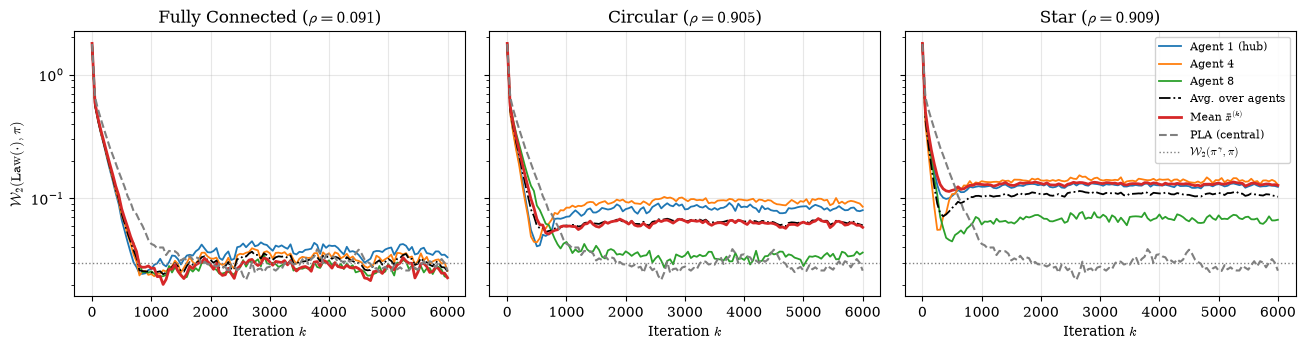

In [5]:
fig, axes = plt.subplots(1, len(NETWORKS), figsize=(4.4 * len(NETWORKS), 3.6), sharey=True, squeeze=False)
for ax, kind in zip(axes[0], NETWORKS):
    r = res[kind]
    for j, i in enumerate(AGENTS_TO_SHOW):
        lab = f"Agent {i+1}" + (" (hub)" if kind == "star" and i == 0 else "")
        ax.plot(iters, r["agents"][:, i], color=COLORS[j], lw=1.3, label=lab)
    ax.plot(iters, r["agents"].mean(1), "k-.", lw=1.3, label="Avg. over agents")
    ax.plot(iters, r["mean"], color=COLORS[3], lw=2, label=r"Mean $\bar x^{(k)}$")
    ax.plot(iters, w2_central, color="gray", ls="--", lw=1.5, label="PLA (central)")
    ax.axhline(floor, color="gray", ls=":", lw=1, label=r"$\mathcal{W}_2(\pi^\gamma,\pi)$")
    ax.set_yscale("log"); ax.set_xlabel("Iteration $k$")
    ax.set_title(f"{NETWORK_NAMES[kind]} ($\\rho={r['rho']:.3f}$)")
axes[0, 0].set_ylabel(r"$\mathcal{W}_2(\mathrm{Law}(\cdot),\pi)$")
axes[0, -1].legend(fontsize=8)
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp1_w2_iterations.{ext}", dpi=200, bbox_inches="tight")

## Densities at the last iteration

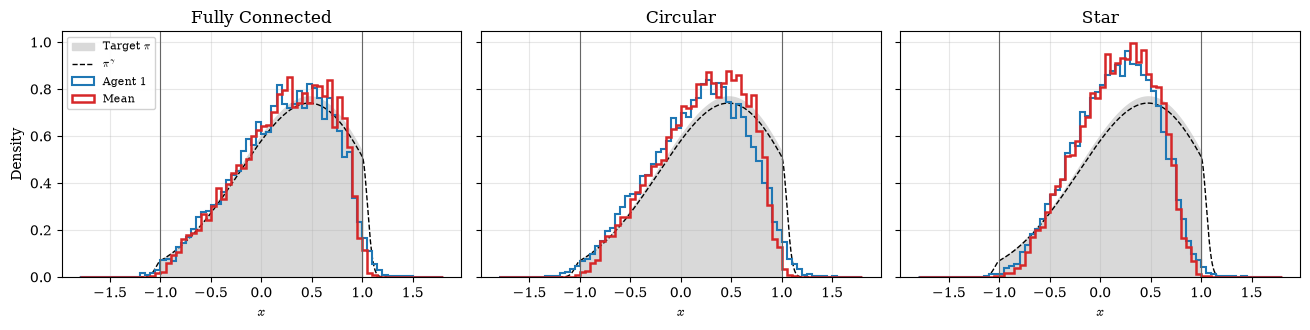

In [6]:
_, g_pi, d_pi = prob.reference()
_, g_g, d_g = prob.reference(GAMMA)
sel = (g_g > -1.8) & (g_g < 1.8)
bins = np.linspace(-1.8, 1.8, 73)
fig, axes = plt.subplots(1, len(NETWORKS), figsize=(4.4 * len(NETWORKS), 3.4), sharey=True, squeeze=False)
for ax, kind in zip(axes[0], NETWORKS):
    xs = res[kind]["final"]
    ax.fill_between(g_pi, d_pi, color="0.85", label=r"Target $\pi$")
    ax.plot(g_g[sel], d_g[sel], "k--", lw=1, label=r"$\pi^\gamma$")
    ax.hist(xs[:, 0], bins=bins, density=True, histtype="step", lw=1.5, color=COLORS[0], label="Agent 1")
    ax.hist(xs.mean(1), bins=bins, density=True, histtype="step", lw=1.8, color=COLORS[3], label="Mean")
    for v in (-1, 1): ax.axvline(v, color="0.4", lw=0.8)
    ax.set_title(NETWORK_NAMES[kind]); ax.set_xlabel("$x$")
axes[0, 0].set_ylabel("Density"); axes[0, 0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp1_densities.{ext}", dpi=200, bbox_inches="tight")

## Summary

In [7]:
rows = []
for kind in NETWORKS:
    r = res[kind]
    rows.append(dict(network=NETWORK_NAMES[kind], rho=r["rho"], W2_mean=r["mean"][-1],
                     W2_agents_avg=r["agents"][-1].mean(),
                     outside_K_agent1=np.mean(np.abs(r["final"][:, 0]) > 1),
                     outside_K_mean=np.mean(np.abs(r["final"].mean(1)) > 1)))
rows.append(dict(network="PSGLD (central)", W2_mean=w2_central[-1]))
pd.DataFrame(rows).round(4)

,network,rho,W2_mean,W2_agents_avg,outside_K_agent1,outside_K_mean
0,Fully Connected,0.0909,0.0227,0.0256,0.0233,0.0081
1,Circular,0.9045,0.0581,0.0604,0.0240,0.0027
2,Star,0.9091,0.1269,0.1027,0.0059,0.0005
3,PSGLD (central),NaN,0.0259,NaN,NaN,NaN


## Stationary error vs $\gamma$ (with $\eta = $ `ETA_FRAC` $\cdot\,\eta_{\max}(\gamma)$)
This cell takes a few minutes for the smallest $\gamma$. Set `RUN_SWEEP = False` to skip it.

  gamma=0.1, Fully Connected: 136/136 iterations (1s)
  gamma=0.1, Circular: 136/136 iterations (1s)
  gamma=0.1, Star: 136/136 iterations (1s)
  gamma=0.03, Fully Connected: 370/370 iterations (2s)
  gamma=0.03, Circular: 370/370 iterations (2s)
  gamma=0.03, Star: 370/370 iterations (2s)
  gamma=0.01, Fully Connected: 1036/1036 iterations (6s)
  gamma=0.01, Circular: 1036/1036 iterations (7s)
  gamma=0.01, Star: 1036/1036 iterations (6s)
  gamma=0.003, Fully Connected: 3370/3370 iterations (19s)
  gamma=0.003, Circular: 3370/3370 iterations (20s)
  gamma=0.003, Star: 3370/3370 iterations (18s)
  gamma=0.001, Fully Connected: 10036/10036 iterations (48s)
  gamma=0.001, Circular: 10036/10036 iterations (47s)
  gamma=0.001, Star: 10036/10036 iterations (48s)


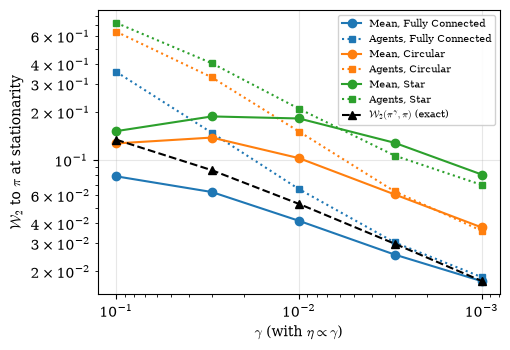

In [8]:
if RUN_SWEEP:
    sweep = {k: {"mean": [], "agents": []} for k in NETWORKS}
    floors = [prob.w2_gamma_pi(g) for g in GAMMAS]
    rng_s = np.random.default_rng(7)
    for g in GAMMAS:
        et = ETA_FRAC * prob.eta_max(g)
        nit = int(RELAX_TIMES * N / (2 * et))
        for kind in NETWORKS:
            W, _, _ = mixing_matrix(kind, N)
            xi = rng_s.uniform(-1, 1, (M_SWEEP, N, 1))
            XT, _ = de_psgld(xi, W, prob.stoch_grad, prob.proj, et, g, nit, seed=7,
                             progress=f"gamma={g:g}, {NETWORK_NAMES[kind]}")
            sweep[kind]["mean"].append(prob.w2_to_pi(XT[:, :, 0].mean(1)))
            sweep[kind]["agents"].append(np.mean([prob.w2_to_pi(XT[:, i, 0]) for i in range(N)]))

    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    for j, kind in enumerate(NETWORKS):
        ax.plot(GAMMAS, sweep[kind]["mean"], "o-", color=COLORS[j], label=f"Mean, {NETWORK_NAMES[kind]}")
        ax.plot(GAMMAS, sweep[kind]["agents"], "s:", color=COLORS[j], ms=4, label=f"Agents, {NETWORK_NAMES[kind]}")
    ax.plot(GAMMAS, floors, "k^--", label=r"$\mathcal{W}_2(\pi^\gamma,\pi)$ (exact)")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.invert_xaxis()   # gamma decreases from left (1e-1) to right (1e-3)
    ax.set_xlabel(r"$\gamma$ (with $\eta\propto\gamma$)"); ax.set_ylabel(r"$\mathcal{W}_2$ to $\pi$ at stationarity")
    ax.legend(fontsize=7); fig.tight_layout()
    if SAVE_FIGS:
        for ext in ("pdf", "png"):
            fig.savefig(FIG_DIR / f"exp1_gamma_sweep.{ext}", dpi=200, bbox_inches="tight")